# 03 - HOG features + six traditional ML models
**Pipeline:** `64x64 RGB image -> grayscale -> HOG (1764 numbers) -> StandardScaler -> classifier`

All six classifiers receive **exactly the same features and the same train/test split**, so the comparison is fair.

![pipeline](../docs/00_project_pipeline.png)

| # | Model | Idea in one line |
|---|---|---|
| 1 | SVM | finds the maximum-margin boundary (RBF kernel) |
| 2 | KNN | votes among the k most similar training images |
| 3 | Random Forest | many decorrelated trees vote |
| 4 | Decision Tree | a single tree of if/else questions on features |
| 5 | Logistic Regression | linear scores + softmax probabilities |
| 6 | Naive Bayes | Bayes rule with independent Gaussian features |

In [25]:
import sys; sys.path.append("..")          # lets the notebook import src/common.py
from src.common import *
import matplotlib.pyplot as plt, numpy as np, pandas as pd
print("Project root:", ROOT)
print("QUICK mode:", QUICK)
import time, joblib
from skimage.color import rgb2gray
from skimage.feature import hog
from skimage import exposure
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV
from scipy.stats import loguniform
from sklearn.metrics import precision_recall_fscore_support

X_train, X_test, y_train, y_test = load_split()
print("train", X_train.shape, "test", X_test.shape)

Project root: C:\Users\ASUS\Desktop\image_classification_project
QUICK mode: False
train (5519, 64, 64, 3) test (1380, 64, 64, 3)


## Step 1 - What is HOG? (one image, step by step)
1. Convert to grayscale.
2. Compute the **gradient** (how fast intensity changes) in x and y -> magnitude + direction = edges.
3. Split the image into **8x8-pixel cells**; in each cell build a histogram of **9 gradient orientations**, weighted by magnitude.
4. Group cells into **2x2 blocks** and normalise (L2-Hys) -> robust to lighting.
5. Concatenate everything: 7x7 blocks x 4 cells x 9 bins = **1764 features** per image.

![HOG](../docs/00_hog_step_by_step.png)

saved -> results\figures\03_hog_step_by_step.png


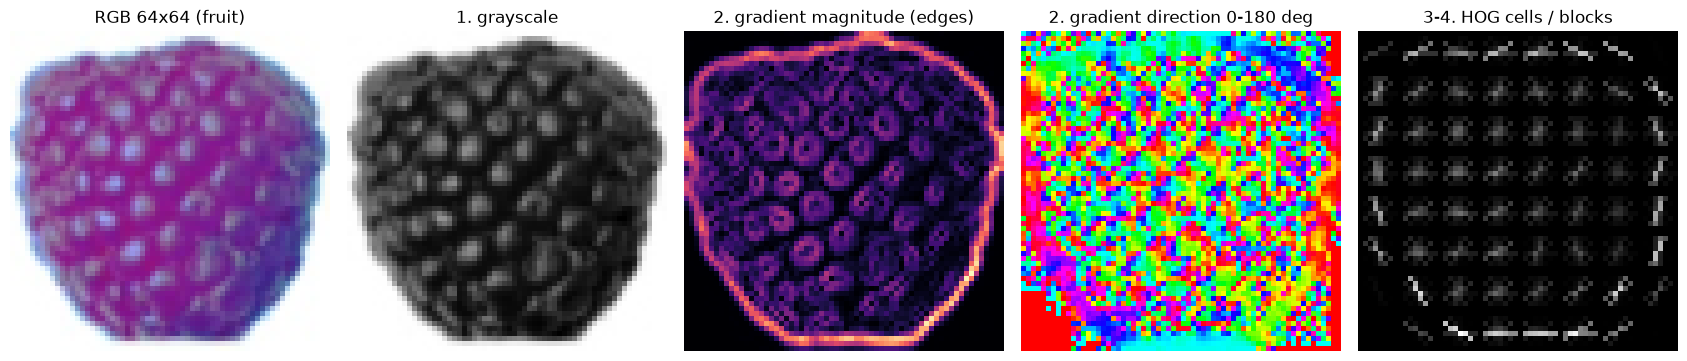

HOG vector length: 1764 = 7 x 7 blocks x 2 x 2 cells x 9 orientations


In [26]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")

img  = X_train[0]
gray = rgb2gray(img / 255.0)
gy, gx = np.gradient(gray)
magnitude   = np.hypot(gx, gy)
orientation = (np.rad2deg(np.arctan2(gy, gx)) % 180)
fd, hog_img = hog(gray, visualize=True, **HOG_PARAMS)

fig, ax = plt.subplots(1, 5, figsize=(17, 3.5))
ax[0].imshow(img);                                  ax[0].set_title(f"RGB 64x64 ({CLASSES[y_train[0]]})")
ax[1].imshow(gray, cmap="gray");                    ax[1].set_title("1. grayscale")
ax[2].imshow(magnitude, cmap="magma");              ax[2].set_title("2. gradient magnitude (edges)")
ax[3].imshow(orientation, cmap="hsv");              ax[3].set_title("2. gradient direction 0-180 deg")
ax[4].imshow(exposure.rescale_intensity(hog_img, in_range=(0, 10)), cmap="gray")
ax[4].set_title("3-4. HOG cells / blocks")
for a in ax: a.axis("off")
plt.tight_layout(); save_fig("03_hog_step_by_step.png"); plt.show()
print("HOG vector length:", fd.shape[0], "= 7 x 7 blocks x 2 x 2 cells x 9 orientations")

## Step 2 - Extract HOG for every image (same code for train and test)

In [15]:
def extract_hog(images, batch=500):
    """images: (N,64,64,3) uint8 -> (N,1764) float32. Batched to save RAM."""
    out = []
    for s in range(0, len(images), batch):
        g = rgb2gray(images[s:s + batch] / 255.0)
        out.extend(hog(im, **HOG_PARAMS) for im in g)
    return np.asarray(out, dtype=np.float32)

t = time.time()
H_train = extract_hog(X_train); H_test = extract_hog(X_test)
print("H_train", H_train.shape, " H_test", H_test.shape, f"({time.time()-t:.0f}s)")
np.savez_compressed(PROC_DIR / "hog_features.npz", H_train=H_train, H_test=H_test,
                    y_train=y_train, y_test=y_test)

H_train (5519, 1764)  H_test (1380, 1764) (5s)


## Step 3 - Standardise
SVM, KNN and Logistic Regression are sensitive to feature scale. The scaler is **fitted on the training set only** (fitting on test data would leak information) and then applied to both.

saved -> results\figures\03_scaling.png


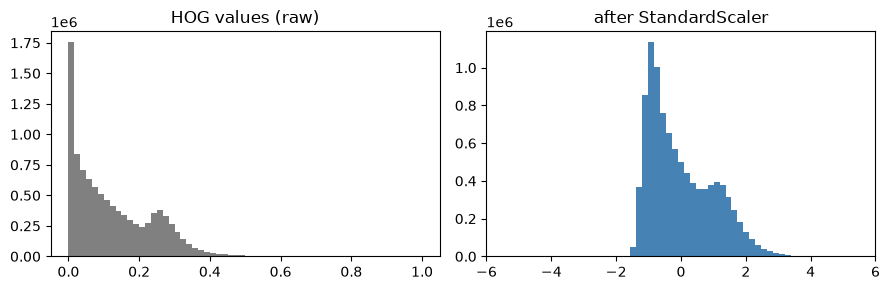

In [16]:
scaler = StandardScaler().fit(H_train)
S_train, S_test = scaler.transform(H_train), scaler.transform(H_test)
joblib.dump(scaler, MODELS_DIR / "hog_scaler.joblib")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(H_train.ravel(), bins=60, color="gray");      ax[0].set_title("HOG values (raw)")
ax[1].hist(S_train.ravel(), bins=60, color="steelblue"); ax[1].set_title("after StandardScaler"); ax[1].set_xlim(-6, 6)
plt.tight_layout(); save_fig("03_scaling.png"); plt.show()

## Step 4 - Train and evaluate the six models
Instead of hand-picking hyperparameters, **scikit-learn searches for them** (`GridSearchCV` / `RandomizedSearchCV`) with 3-fold cross-validation **on the training set only**, scored by macro-F1. The best setting is refit on the whole training set and then evaluated once on the test set.

The helper `tune()` does the search; `run()` trains/evaluates and saves the model.

In [17]:
FAMILY = "Traditional ML"
results, preds, best_params, searches = [], {}, {}, {}
N_ITER = 6 if QUICK else 15          # random-search budget for the expensive models (SVM, Random Forest)

def run(name, model, prefit_time=None):
    """Evaluate a model. If a search already fitted it, pass its fit time instead of refitting."""
    if prefit_time is None:
        t = time.time(); model.fit(S_train, y_train); train_time = time.time() - t
    else:
        train_time = prefit_time
    y_pred = model.predict(S_test); preds[name] = y_pred
    joblib.dump(model, MODELS_DIR / f"{slug(name)}.joblib")
    results.append(evaluate(name, FAMILY, y_test, y_pred, train_time))
    return model

def tune(name, model, params, n_iter=None, cv=3):
    """Let scikit-learn pick the hyperparameters (train set only).
    n_iter=None -> exhaustive GridSearchCV; n_iter=int -> RandomizedSearchCV."""
    common = dict(cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
    if n_iter is None:
        search = GridSearchCV(model, params, **common)
    else:
        search = RandomizedSearchCV(model, params, n_iter=n_iter, random_state=SEED, **common)
    t = time.time(); search.fit(S_train, y_train); search_time = time.time() - t
    best_params[name] = search.best_params_; searches[name] = search
    print(f"{name}: best params = {search.best_params_} | CV macro-F1 = {search.best_score_:.4f} (search took {search_time:.0f}s)")
    return run(name, search.best_estimator_, prefit_time=search.refit_time_)   # time of the final fit only

def block_map(vec):
    """Sum a 1764-long HOG-sized vector over cells/orientations -> 7x7 spatial map."""
    return np.asarray(vec).reshape(7, 7, 2, 2, 9).sum(axis=(2, 3, 4))

## 4.1 - SVM
![SVM](../docs/model_steps/01_svm.png)

RBF-kernel SVM; `C` and `gamma` are found by a randomized search on a log scale. Below: the 2-D PCA view of the HOG space and the number of support vectors per class (the images that define the boundary).

SVM: best params = {'C': np.float64(15.702970884055382), 'gamma': np.float64(0.0006251373574521745)} | CV macro-F1 = 0.8713 (search took 217s)
=== SVM ===   accuracy=0.8913  precision=0.8917  recall=0.8913  F1=0.8912
              precision    recall  f1-score   support

    airplane       0.99      0.96      0.98       145
         car       0.98      1.00      0.99       194
         cat       0.70      0.74      0.72       177
         dog       0.68      0.61      0.65       140
      flower       0.73      0.75      0.74       169
       fruit       1.00      0.99      1.00       200
   motorbike       1.00      1.00      1.00       158
      person       0.99      0.99      0.99       197

    accuracy                           0.89      1380
   macro avg       0.88      0.88      0.88      1380
weighted avg       0.89      0.89      0.89      1380

saved -> results\figures\cm_svm.png


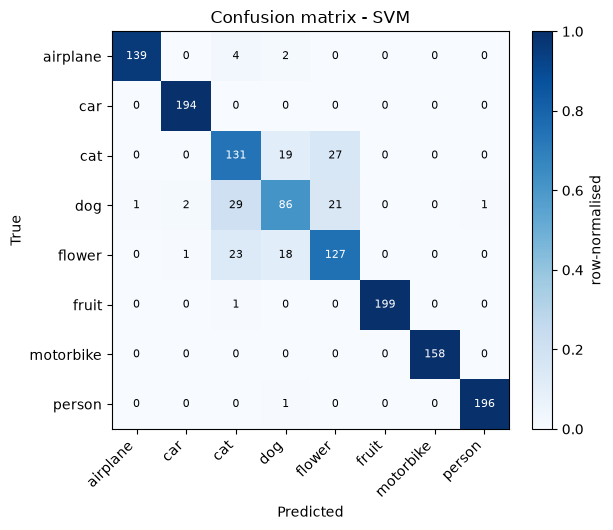

saved -> results\figures\03_svm_process.png


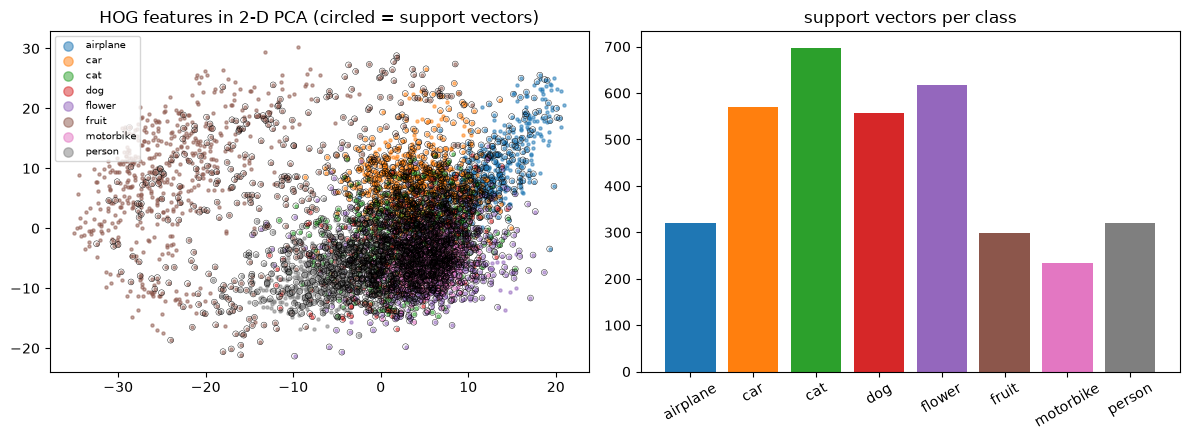

In [18]:
svm = tune("SVM", SVC(kernel="rbf"),
           {"C": loguniform(1e-1, 1e2), "gamma": loguniform(1e-5, 1e-2)}, n_iter=N_ITER)

pca = PCA(2, random_state=SEED).fit(S_train); P = pca.transform(S_train)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, cls in enumerate(CLASSES):
    ax[0].scatter(*P[y_train == i].T, s=5, alpha=.5, label=cls, color=plt.cm.tab10.colors[i])
ax[0].scatter(*P[svm.support_].T, s=18, facecolors="none", edgecolors="k", linewidths=.3)
ax[0].set_title("HOG features in 2-D PCA (circled = support vectors)"); ax[0].legend(markerscale=3, fontsize=7)
ax[1].bar(CLASSES, svm.n_support_, color=plt.cm.tab10.colors[:8]); ax[1].set_title("support vectors per class")
plt.setp(ax[1].get_xticklabels(), rotation=30); plt.tight_layout(); save_fig("03_svm_process.png"); plt.show()

## 4.2 - KNN
![KNN](../docs/model_steps/02_knn.png)

The number of neighbours `k` and the vote weighting are chosen by grid search with 3-fold cross-validation **on the training set only**.

KNN: best params = {'n_neighbors': 1, 'weights': 'uniform'} | CV macro-F1 = 0.7129 (search took 4s)
=== KNN ===   accuracy=0.7638  precision=0.8208  recall=0.7638  F1=0.7295
              precision    recall  f1-score   support

    airplane       0.99      0.92      0.96       145
         car       1.00      0.96      0.98       194
         cat       0.86      0.14      0.23       177
         dog       0.31      0.03      0.05       140
      flower       0.35      0.96      0.52       169
       fruit       0.96      1.00      0.98       200
   motorbike       0.97      0.97      0.97       158
      person       0.99      0.96      0.98       197

    accuracy                           0.76      1380
   macro avg       0.80      0.74      0.71      1380
weighted avg       0.82      0.76      0.73      1380

saved -> results\figures\cm_knn.png


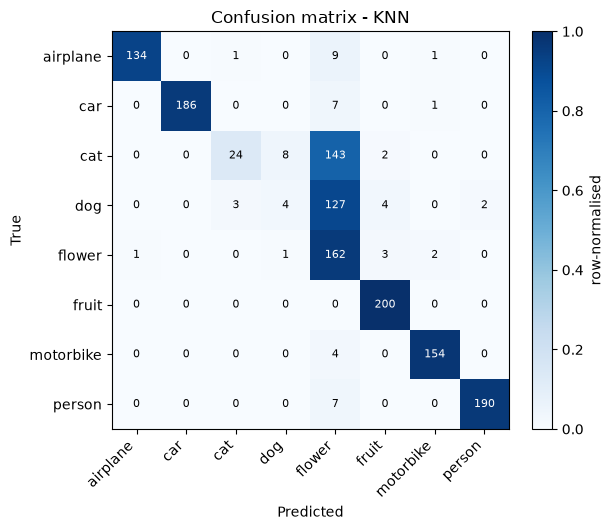

saved -> results\figures\03_knn_k_selection.png


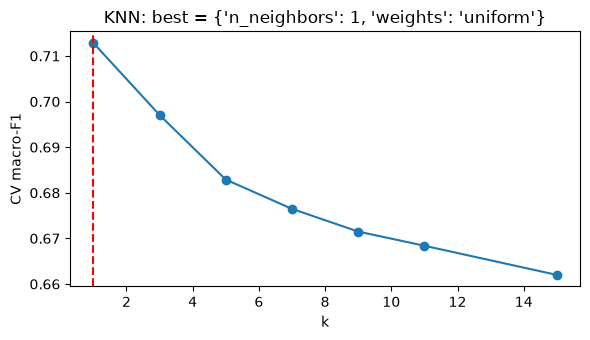

In [19]:
knn = tune("KNN", KNeighborsClassifier(),
           {"n_neighbors": [1, 3, 5, 7, 9, 11, 15], "weights": ["uniform", "distance"]})

cvr = pd.DataFrame(searches["KNN"].cv_results_)
curve = cvr.groupby("param_n_neighbors")["mean_test_score"].max()
plt.figure(figsize=(6, 3.5)); plt.plot(curve.index.astype(int), curve.values, "o-")
plt.axvline(best_params["KNN"]["n_neighbors"], color="r", ls="--")
plt.xlabel("k"); plt.ylabel("CV macro-F1"); plt.title(f"KNN: best = {best_params['KNN']}")
plt.tight_layout(); save_fig("03_knn_k_selection.png"); plt.show()

## 4.3 - Random Forest
![Random Forest](../docs/model_steps/03_random_forest.png)

Many trees, each trained on a bootstrap sample with random feature subsets; the forest settings are found by randomized search. The importance map shows *which image regions* the forest relies on.

Random Forest: best params = {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20} | CV macro-F1 = 0.8055 (search took 54s)
=== Random Forest ===   accuracy=0.8522  precision=0.8499  recall=0.8522  F1=0.8421
              precision    recall  f1-score   support

    airplane       0.99      0.95      0.97       145
         car       0.85      1.00      0.92       194
         cat       0.59      0.70      0.64       177
         dog       0.70      0.31      0.43       140
      flower       0.70      0.72      0.71       169
       fruit       0.98      1.00      0.99       200
   motorbike       0.99      0.99      0.99       158
      person       0.97      1.00      0.98       197

    accuracy                           0.85      1380
   macro avg       0.85      0.84      0.83      1380
weighted avg       0.85      0.85      0.84      1380

saved -> results\figures\cm_random_forest.png


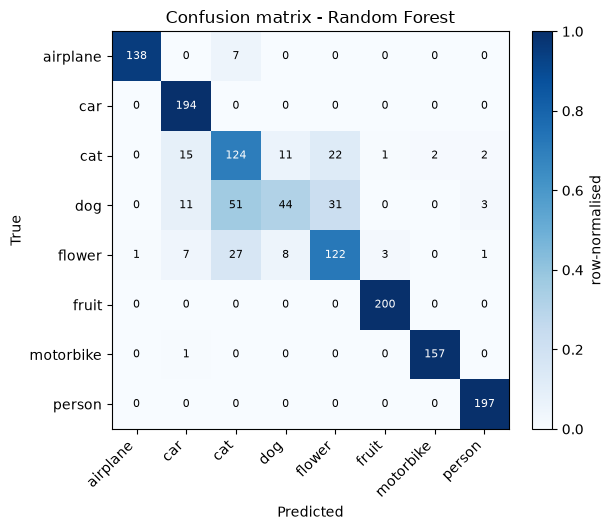

saved -> results\figures\03_rf_importance.png


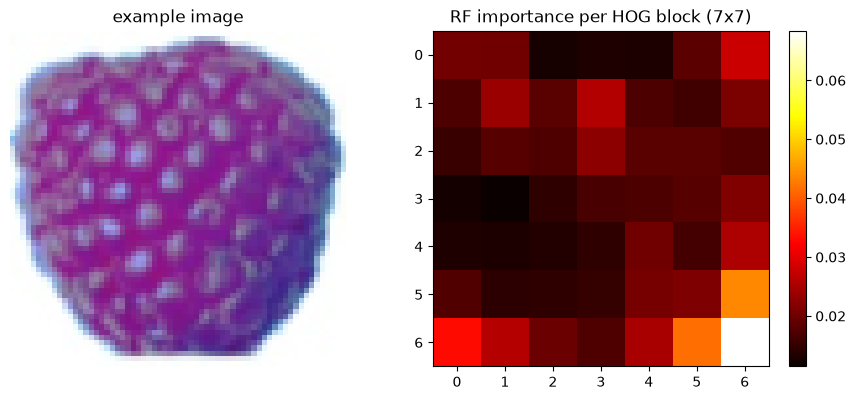

In [20]:
rf = tune("Random Forest", RandomForestClassifier(n_jobs=-1, random_state=SEED),
          {"n_estimators": [100, 200, 300], "max_depth": [None, 20, 40],
           "max_features": ["sqrt", "log2"], "min_samples_leaf": [1, 2, 4]}, n_iter=N_ITER)

imp = block_map(rf.feature_importances_)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(X_train[0]); ax[0].set_title("example image"); ax[0].axis("off")
im = ax[1].imshow(imp, cmap="hot"); ax[1].set_title("RF importance per HOG block (7x7)")
plt.colorbar(im, ax=ax[1], fraction=.046); plt.tight_layout(); save_fig("03_rf_importance.png"); plt.show()

## 4.4 - Decision Tree
![Decision Tree](../docs/model_steps/04_decision_tree.png)

A single tree. Depth and minimum leaf size are selected by grid search with 3-fold CV on the training set (an unlimited tree memorises the training data).

Decision Tree: best params = {'max_depth': 12, 'min_samples_leaf': 5} | CV macro-F1 = 0.6041 (search took 29s)
=== Decision Tree ===   accuracy=0.6275  precision=0.6440  recall=0.6275  F1=0.6346
              precision    recall  f1-score   support

    airplane       0.79      0.77      0.78       145
         car       0.61      0.62      0.62       194
         cat       0.31      0.31      0.31       177
         dog       0.27      0.33      0.30       140
      flower       0.48      0.49      0.48       169
       fruit       0.98      0.94      0.96       200
   motorbike       0.73      0.73      0.73       158
      person       0.87      0.74      0.80       197

    accuracy                           0.63      1380
   macro avg       0.63      0.62      0.62      1380
weighted avg       0.64      0.63      0.63      1380

saved -> results\figures\cm_decision_tree.png


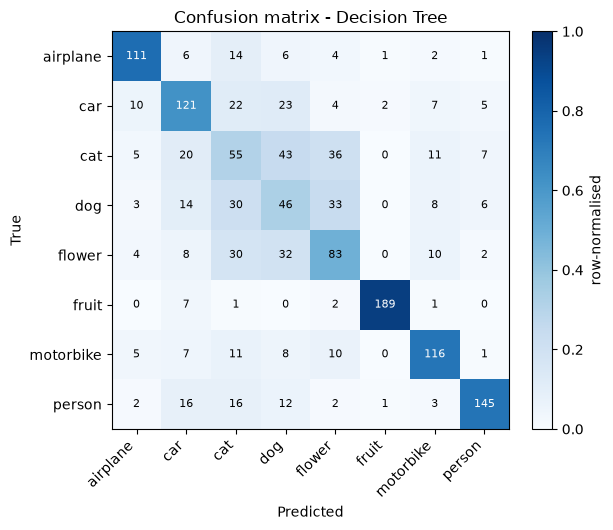

saved -> results\figures\03_dt_depth_selection.png


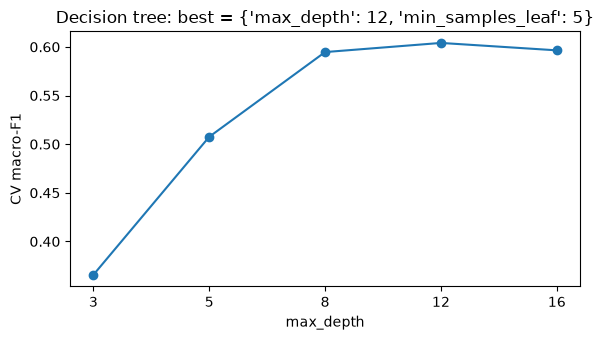

saved -> results\figures\03_dt_tree_top.png


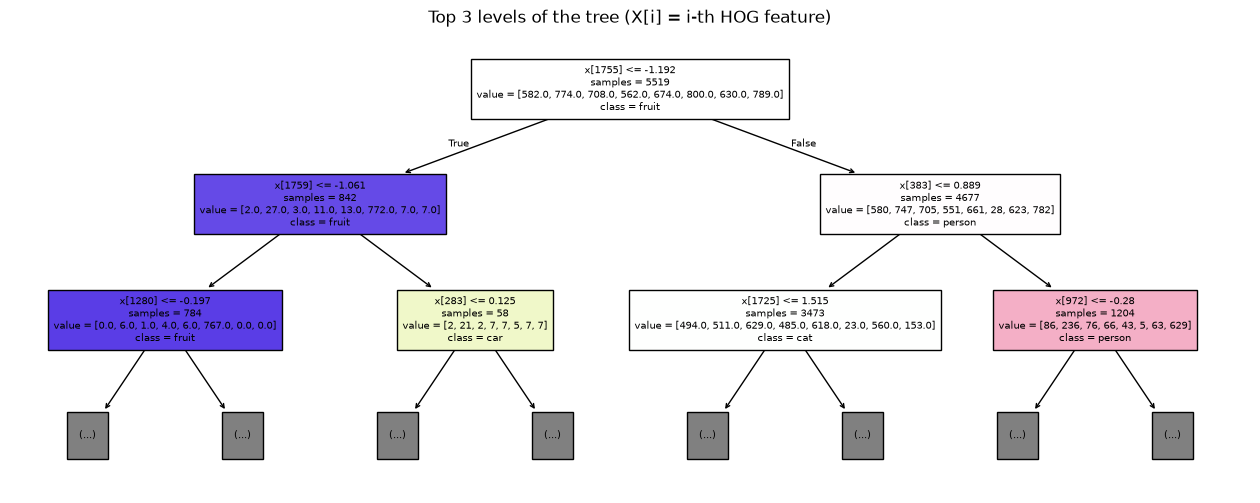

In [21]:
dt = tune("Decision Tree", DecisionTreeClassifier(random_state=SEED),
          {"max_depth": [3, 5, 8, 12, 16, None], "min_samples_leaf": [1, 5, 10]})

cvr = pd.DataFrame(searches["Decision Tree"].cv_results_)
curve = cvr.groupby(cvr["param_max_depth"].astype(str), sort=False)["mean_test_score"].max()
plt.figure(figsize=(6, 3.5)); plt.plot(curve.index, curve.values, "o-")
plt.xlabel("max_depth"); plt.ylabel("CV macro-F1"); plt.title(f"Decision tree: best = {best_params['Decision Tree']}")
plt.tight_layout(); save_fig("03_dt_depth_selection.png"); plt.show()

plt.figure(figsize=(16, 6)); plot_tree(dt, max_depth=2, class_names=CLASSES, filled=True, fontsize=7, impurity=False)
plt.title("Top 3 levels of the tree (X[i] = i-th HOG feature)"); save_fig("03_dt_tree_top.png"); plt.show()

## 4.5 - Logistic Regression
![Logistic Regression](../docs/model_steps/05_logistic_regression.png)

Multinomial logistic regression (regularisation strength `C` chosen by grid search): one weight vector per class, softmax turns the 8 scores into probabilities. The maps show where in the image each class's weights are large.

Logistic Regression: best params = {'C': 0.01} | CV macro-F1 = 0.8236 (search took 8s)
=== Logistic Regression ===   accuracy=0.8529  precision=0.8542  recall=0.8529  F1=0.8535
              precision    recall  f1-score   support

    airplane       0.97      0.97      0.97       145
         car       0.95      0.95      0.95       194
         cat       0.66      0.64      0.65       177
         dog       0.55      0.59      0.57       140
      flower       0.64      0.64      0.64       169
       fruit       0.99      0.99      0.99       200
   motorbike       1.00      0.99      1.00       158
      person       0.99      0.98      0.99       197

    accuracy                           0.85      1380
   macro avg       0.84      0.84      0.84      1380
weighted avg       0.85      0.85      0.85      1380

saved -> results\figures\cm_logistic_regression.png


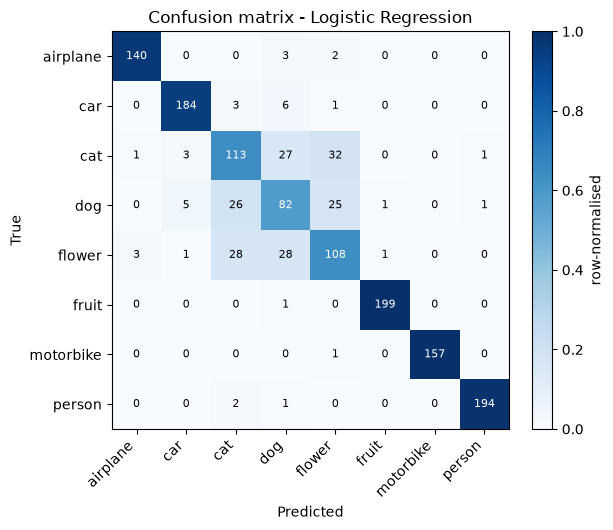

saved -> results\figures\03_lr_weights.png


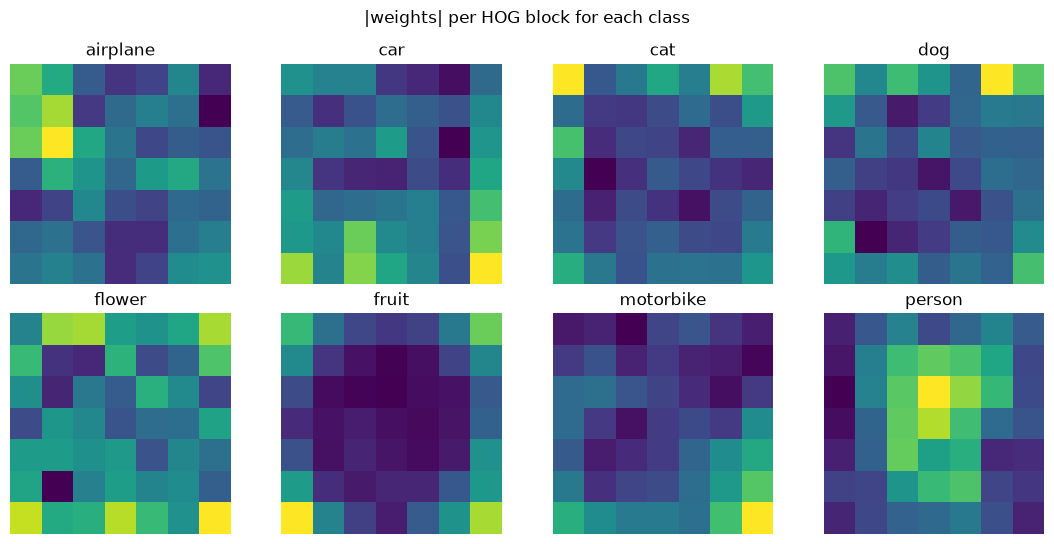

In [22]:
lr = tune("Logistic Regression", LogisticRegression(max_iter=1000), {"C": [0.01, 0.1, 1, 10]})

maps = np.abs(lr.coef_).reshape(len(CLASSES), 7, 7, 2, 2, 9).mean(axis=(3, 4, 5))
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for a, m, cls in zip(axes.ravel(), maps, CLASSES):
    a.imshow(m, cmap="viridis"); a.set_title(cls); a.axis("off")
plt.suptitle("|weights| per HOG block for each class"); plt.tight_layout()
save_fig("03_lr_weights.png"); plt.show()

## 4.6 - Naive Bayes
![Naive Bayes](../docs/model_steps/06_naive_bayes.png)

Gaussian Naive Bayes (`var_smoothing` chosen by grid search): for each class it learns a mean and variance per HOG feature, then multiplies the (assumed independent) likelihoods with the class prior.

Naive Bayes: best params = {'var_smoothing': np.float64(1e-11)} | CV macro-F1 = 0.8133 (search took 2s)
=== Naive Bayes ===   accuracy=0.8217  precision=0.8326  recall=0.8217  F1=0.8256
              precision    recall  f1-score   support

    airplane       0.99      0.91      0.95       145
         car       0.88      0.95      0.92       194
         cat       0.58      0.59      0.58       177
         dog       0.60      0.56      0.58       140
      flower       0.56      0.68      0.61       169
       fruit       1.00      0.92      0.96       200
   motorbike       1.00      0.94      0.97       158
      person       0.99      0.96      0.98       197

    accuracy                           0.82      1380
   macro avg       0.82      0.81      0.82      1380
weighted avg       0.83      0.82      0.83      1380

saved -> results\figures\cm_naive_bayes.png


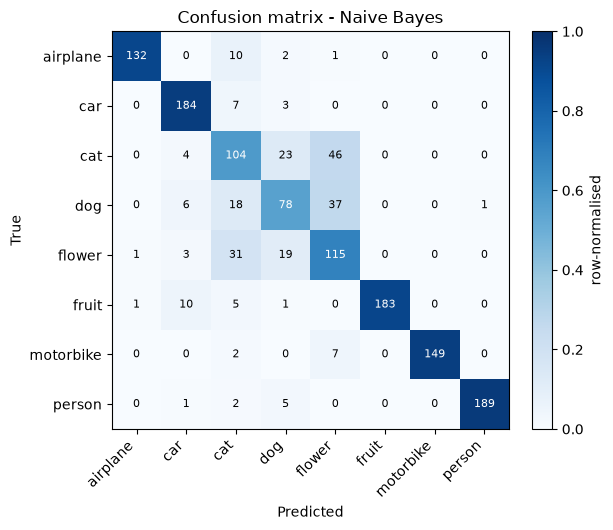

saved -> results\figures\03_nb_class_means.png


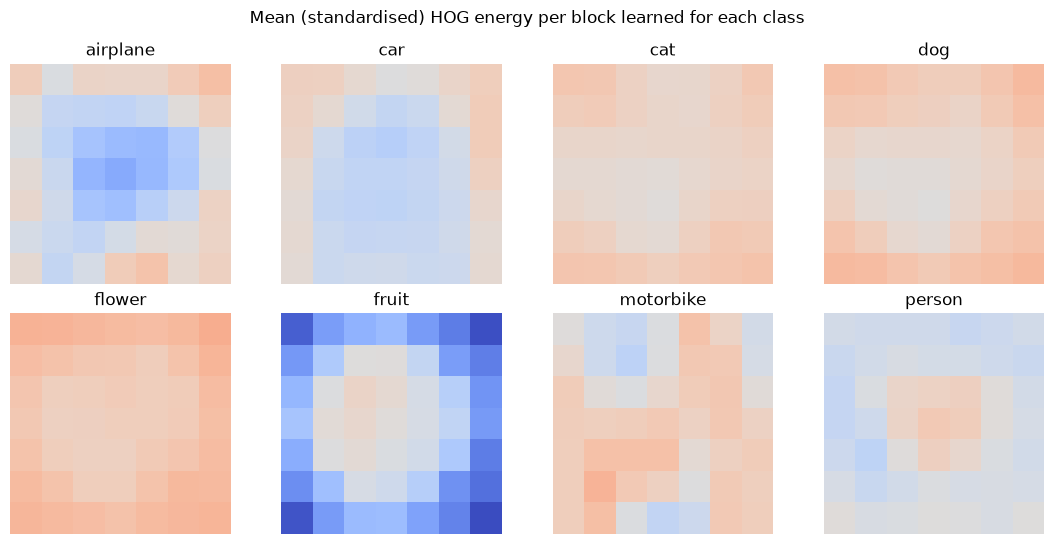

In [23]:
nb = tune("Naive Bayes", GaussianNB(), {"var_smoothing": np.logspace(-11, -1, 11)})

maps = nb.theta_.reshape(len(CLASSES), 7, 7, 2, 2, 9).mean(axis=(3, 4, 5))
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for a, m, cls in zip(axes.ravel(), maps, CLASSES):
    a.imshow(m, cmap="coolwarm", vmin=-.5, vmax=.5); a.set_title(cls); a.axis("off")
plt.suptitle("Mean (standardised) HOG energy per block learned for each class"); plt.tight_layout()
save_fig("03_nb_class_means.png"); plt.show()

## Step 5 - Compare the six traditional models

,model,family,accuracy,precision,recall,f1_score,train_time_s
0,SVM,Traditional ML,0.8913,0.8917,0.8913,0.8912,7.4
1,Logistic Regression,Traditional ML,0.8529,0.8542,0.8529,0.8535,6.0
2,Random Forest,Traditional ML,0.8522,0.8499,0.8522,0.8421,2.9
3,Naive Bayes,Traditional ML,0.8217,0.8326,0.8217,0.8256,0.0
4,KNN,Traditional ML,0.7638,0.8208,0.7638,0.7295,0.0
5,Decision Tree,Traditional ML,0.6275,0.6440,0.6275,0.6346,5.3


Hyperparameters selected by scikit-learn:


,best params
SVM,"{'C': 15.702970884055382, 'gamma': 0.000625137..."
KNN,"{'n_neighbors': 1, 'weights': 'uniform'}"
Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 1, '..."
Decision Tree,"{'max_depth': 12, 'min_samples_leaf': 5}"
Logistic Regression,{'C': 0.01}
Naive Bayes,{'var_smoothing': 1e-11}


saved -> results\figures\03_traditional_comparison.png


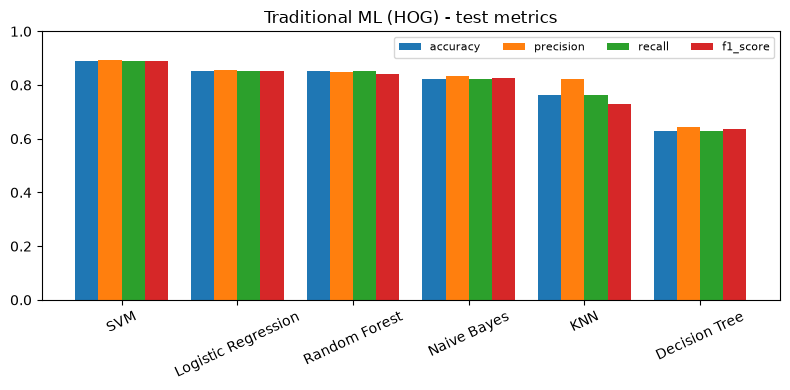

saved -> results\figures\03_f1_per_class.png


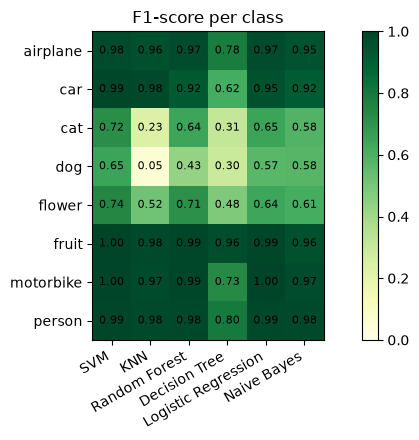

In [24]:
df = pd.DataFrame(results).sort_values("f1_score", ascending=False).reset_index(drop=True)
display(df.round(4))
print("Hyperparameters selected by scikit-learn:")
display(pd.Series(best_params, name="best params").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(df)); w = 0.2
for i, m in enumerate(["accuracy", "precision", "recall", "f1_score"]):
    ax.bar(x + (i - 1.5) * w, df[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(df["model"], rotation=25); ax.set_ylim(0, 1); ax.legend(ncol=4, fontsize=8)
ax.set_title("Traditional ML (HOG) - test metrics"); plt.tight_layout(); save_fig("03_traditional_comparison.png"); plt.show()

# per-class F1
f1 = pd.DataFrame({n: precision_recall_fscore_support(y_test, p, labels=range(len(CLASSES)), zero_division=0)[2]
                   for n, p in preds.items()}, index=CLASSES)
plt.figure(figsize=(8, 4.5)); plt.imshow(f1.values, cmap="YlGn", vmin=0, vmax=1)
plt.xticks(range(f1.shape[1]), f1.columns, rotation=30, ha="right"); plt.yticks(range(len(CLASSES)), CLASSES)
for i in range(f1.shape[0]):
    for j in range(f1.shape[1]): plt.text(j, i, f"{f1.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("F1-score per class"); plt.colorbar(); plt.tight_layout(); save_fig("03_f1_per_class.png"); plt.show()

## Next
`04_deep_learning.ipynb` trains the MLP and the CNN directly on the images. All metrics are already stored in `results/metrics/`.